# Final Project: Popularity Bias in Recommender Systems

This notebook evaluates recommendation accuracy and popularity bias using a chronological split, compares baseline models, and tests two post-training debiasing strategies:
1. **Popularity-penalty reranking** – subtracts a popularity penalty from model scores.
2. **User-adaptive reranking** – adjusts the popularity penalty based on the user's history (users with more head-item history receive a stronger penalty).


## 1. Experimental design and reproducibility
- Dataset: MovieLens 1M ratings.
- Positive feedback: ratings >= 4.
- Iterative 5-core filtering: users and items with fewer than 5 positive interactions are removed.
- Chronological 80/10/10 train/validation/test split.
- Full-catalog ranking; previously observed items are excluded.
- Metrics: Recall@10/20, NDCG@10/20, ARP@10, tail share@10, catalog coverage@10, and Gini@10.
- Validation data is used to select hyperparameters. Test data is held for final evaluation.

In [ ]:
import os, urllib.request, zipfile, ssl, random, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
DATA_DIR = "data"
TOPK = (10, 20)
np.random.seed(SEED)
random.seed(SEED)

## 2. Load, clean, and split the data

In [ ]:
ML1M_URL = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"

def load_ml1m(data_dir=DATA_DIR):
    ratings_path = os.path.join(data_dir, "ml-1m", "ratings.dat")
    if not os.path.exists(ratings_path):
        os.makedirs(data_dir, exist_ok=True)
        zip_path = os.path.join(data_dir, "ml-1m.zip")
        print("Downloading MovieLens 1M...")
        ctx = ssl._create_unverified_context()
        with urllib.request.urlopen(ML1M_URL, context=ctx) as r, open(zip_path, "wb") as f:
            f.write(r.read())
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(data_dir)
    return pd.read_csv(ratings_path, sep="::", engine="python",
                       names=["user", "item", "rating", "ts"])

def kcore(data, k=5):
    data = data.copy()
    while True:
        uc = data.user.value_counts()
        ic = data.item.value_counts()
        keep = data.user.map(uc).ge(k) & data.item.map(ic).ge(k)
        if keep.all():
            return data
        data = data.loc[keep].copy()

def prepare_data(raw, min_rating=4, k=5):
    d = kcore(raw.loc[raw.rating >= min_rating].copy(), k)
    d["user"], user_ids = pd.factorize(d.user)
    d["item"], item_ids = pd.factorize(d.item)
    d = d.sort_values("ts", kind="stable").reset_index(drop=True)
    n = len(d); i1, i2 = int(.8*n), int(.9*n)
    train, val, test = d.iloc[:i1].copy(), d.iloc[i1:i2].copy(), d.iloc[i2:].copy()
    return train, val, test, len(user_ids), len(item_ids)

def csr(data, n_users, n_items):
    mat = sp.csr_matrix((np.ones(len(data), dtype=np.float32),
                         (data.user, data.item)), shape=(n_users, n_items))
    mat.data[:] = 1
    return mat

raw = load_ml1m()
train, val, test, n_users, n_items = prepare_data(raw)
X_train = csr(train, n_users, n_items)
X_trval = csr(pd.concat([train, val]), n_users, n_items)
item_pop = np.asarray(X_train.sum(axis=0)).ravel().astype(np.float32)
head_mask = np.zeros(n_items, dtype=bool)
head_mask[np.argsort(-item_pop)[:max(1, int(.2*n_items))]] = True
print(f"Raw ratings: {len(raw):,}")
print(f"Positive 5-core interactions: {len(train)+len(val)+len(test):,}")
print(f"Users: {n_users:,} | Items: {n_items:,}")
print(f"Train: {len(train):,} | Validation: {len(val):,} | Test: {len(test):,}")
display(pd.DataFrame({"split":["Train","Validation","Test"],"interactions":[len(train),len(val),len(test)]}))

Raw ratings: 1,000,209
Positive 5-core interactions: 574,376
Users: 6,034 | Items: 3,125
Train: 459,500 | Validation: 57,438 | Test: 57,438


,split,interactions
0,Train,459500
1,Validation,57438
2,Test,57438


## 3. Evaluation metrics

In [ ]:
def gini(counts):
    counts = np.sort(np.asarray(counts, dtype=np.float64))
    if counts.sum() == 0: return 0.0
    n = len(counts)
    return float((2*np.arange(1,n+1)*counts).sum()/(n*counts.sum())-(n+1)/n)

def get_topk(scores, seen, k=20):
    scores = np.asarray(scores).copy()
    seen_coo = seen.tocoo()
    scores[seen_coo.row, seen_coo.col] = -np.inf
    k = min(k, scores.shape[1])
    idx = np.argpartition(-scores, k-1, axis=1)[:, :k]
    vals = np.take_along_axis(scores, idx, axis=1)
    order = np.argsort(-vals, axis=1)
    return np.take_along_axis(idx, order, axis=1)

def evaluate_scores(score_fn, seen, targets, popularity, head, ks=(10,20), batch=256):
    target_dict = targets.groupby("user").item.apply(set).to_dict()
    users = np.array([u for u in target_dict if seen[u].nnz > 0], dtype=int)
    maxk=max(ks); top_rows=[]
    recalls={k:[] for k in ks}; ndcgs={k:[] for k in ks}
    discounts=1/np.log2(np.arange(2,maxk+2))
    for start in range(0,len(users),batch):
        ub=users[start:start+batch]
        scores=score_fn(ub)
        seen_batch=seen[ub]
        top=get_topk(scores,seen_batch,maxk)
        top_rows.append(top)
        for u,row in zip(ub,top):
            rel=np.array([it in target_dict[u] for it in row],dtype=float)
            for k in ks:
                recalls[k].append(rel[:k].sum()/max(1,len(target_dict[u])))
                ideal=discounts[:min(k,len(target_dict[u]))].sum()
                ndcgs[k].append((rel[:k]*discounts[:k]).sum()/ideal if ideal else 0)
    top=np.vstack(top_rows)
    counts=np.bincount(top[:,:10].ravel(),minlength=seen.shape[1])
    out={f"Recall@{k}":np.mean(recalls[k]) for k in ks}
    out.update({f"NDCG@{k}":np.mean(ndcgs[k]) for k in ks})
    out.update({"ARP@10":float(popularity[top[:,:10]].mean()),
                "TailShare@10":float(1-head[top[:,:10]].mean()),
                "Coverage@10":float(np.count_nonzero(counts)/seen.shape[1]),
                "Gini@10":gini(counts),
                "EvalUsers":len(users)})
    return out, top, users

def group_metrics(top, users, user_group, popularity, head):
    rows=[]
    for group in sorted(pd.unique(user_group[users])):
        idx=np.where(user_group[users]==group)[0]
        lists=top[idx,:10]
        counts=np.bincount(lists.ravel(),minlength=len(popularity))
        rows.append({"UserGroup":group,"Users":len(idx),
                    "ARP@10":popularity[lists].mean(),
                    "TailShare@10":1-head[lists].mean(),
                    "Coverage@10":np.count_nonzero(counts)/len(popularity),
                    "Gini@10":gini(counts)})
    return pd.DataFrame(rows)

## 4. Baseline recommenders

In [ ]:
class MostPopular:
    def fit(self, X):
        self.pop=np.asarray(X.sum(axis=0)).ravel().astype(np.float32)
    def score(self, users):
        return np.tile(self.pop,(len(users),1))

class ItemKNN:
    def __init__(self,k=100,shrink=10):
        self.k,self.shrink=k,shrink
    def fit(self,X):
        co=(X.T@X).toarray().astype(np.float32)
        norms=np.sqrt(np.asarray(X.sum(axis=0)).ravel())
        S=co/(np.outer(norms,norms)+self.shrink)
        np.fill_diagonal(S,0)
        if self.k<S.shape[0]:
            drop=np.argpartition(-S,self.k,axis=1)[:,self.k:]
            np.put_along_axis(S,drop,0,axis=1)
        self.S=S
        self.X=X
    def score(self,users):
        return np.asarray(self.X[users]@self.S)

class MFBPR:
    def __init__(self,dim=64,lr=0.005,reg=1e-4,epochs=30,batch=2048,seed=SEED):
        self.dim,self.lr,self.reg,self.epochs,self.batch,self.seed=dim,lr,reg,epochs,batch,seed
    def fit(self,X):
        import torch
        import torch.nn.functional as F
        torch.manual_seed(self.seed)
        coo=X.tocoo()
        users=torch.tensor(coo.row,dtype=torch.long)
        pos=torch.tensor(coo.col,dtype=torch.long)
        U=torch.nn.Embedding(X.shape[0],self.dim)
        V=torch.nn.Embedding(X.shape[1],self.dim)
        torch.nn.init.normal_(U.weight,std=.1); torch.nn.init.normal_(V.weight,std=.1)
        opt=torch.optim.Adam(list(U.parameters())+list(V.parameters()),lr=self.lr)
        for epoch in range(self.epochs):
            perm=torch.randperm(len(users))
            loss_sum=0
            for s in range(0,len(perm),self.batch):
                b=perm[s:s+self.batch]
                u,p=users[b],pos[b]
                n=torch.randint(0,X.shape[1],(len(b),))
                eu,ep,en=U(u),V(p),V(n)
                loss=-F.logsigmoid((eu*(ep-en)).sum(1)).mean()+self.reg*(eu.square().sum(1)+ep.square().sum(1)+en.square().sum(1)).mean()
                opt.zero_grad(); loss.backward(); opt.step()
                loss_sum+=loss.item()*len(b)
            print(f"Epoch {epoch+1:02d}/{self.epochs} | loss {loss_sum/len(users):.4f}")
        self.Uw=U.weight.detach().cpu().numpy(); self.Vw=V.weight.detach().cpu().numpy()
    def score(self,users):
        return self.Uw[users]@self.Vw.T

## 5. Baseline validation and final test results

In [ ]:
# Re-assign and fit the baseline models properly so they don't resolve to None
baseline_models = {}

baseline_models["Most-popular"] = MostPopular()
baseline_models["Most-popular"].fit(X_train)

baseline_models["Item-kNN"] = ItemKNN(k=100, shrink=10)
baseline_models["Item-kNN"].fit(X_train)

baseline_models["MF-BPR"] = MFBPR(epochs=30)
baseline_models["MF-BPR"].fit(X_train)

baseline_val={}
for name,model in baseline_models.items():
    r,_,_=evaluate_scores(model.score,X_train,val,item_pop,head_mask)
    baseline_val[name]=r
baseline_val_df=pd.DataFrame(baseline_val).T
display(baseline_val_df.round(4))

baseline_test={}
baseline_top={}
for name,model in baseline_models.items():
    r,top,users=evaluate_scores(model.score,X_trval,test,item_pop,head_mask)
    baseline_test[name]=r; baseline_top[name]=top
baseline_results=pd.DataFrame(baseline_test).T
display(baseline_results.round(4))

Epoch 01/30 | loss 0.5995
Epoch 02/30 | loss 0.3354
Epoch 03/30 | loss 0.2712
Epoch 04/30 | loss 0.2371
Epoch 05/30 | loss 0.2166
Epoch 06/30 | loss 0.2030
Epoch 07/30 | loss 0.1915
Epoch 08/30 | loss 0.1848
Epoch 09/30 | loss 0.1776
Epoch 10/30 | loss 0.1719
Epoch 11/30 | loss 0.1684
Epoch 12/30 | loss 0.1635
Epoch 13/30 | loss 0.1615
Epoch 14/30 | loss 0.1577
Epoch 15/30 | loss 0.1565
Epoch 16/30 | loss 0.1539
Epoch 17/30 | loss 0.1521
Epoch 18/30 | loss 0.1514
Epoch 19/30 | loss 0.1496
Epoch 20/30 | loss 0.1493
Epoch 21/30 | loss 0.1469
Epoch 22/30 | loss 0.1468
Epoch 23/30 | loss 0.1447
Epoch 24/30 | loss 0.1447
Epoch 25/30 | loss 0.1442
Epoch 26/30 | loss 0.1432
Epoch 27/30 | loss 0.1413
Epoch 28/30 | loss 0.1415
Epoch 29/30 | loss 0.1417
Epoch 30/30 | loss 0.1413


,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
Most-popular,0.0460,0.0736,0.1163,0.1152,1732.7148,0.0000,0.0275,0.9921,490.0
Item-kNN,0.0477,0.0800,0.1248,0.1230,1467.9039,0.0000,0.0464,0.9852,490.0
MF-BPR,0.0345,0.0706,0.0704,0.0805,599.4535,0.2692,0.4086,0.8010,490.0


,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
Most-popular,0.0451,0.0788,0.1773,0.1711,1743.2056,0.0000,0.0307,0.9923,1154.0
Item-kNN,0.0415,0.0702,0.1599,0.1547,1256.8788,0.1407,0.0861,0.9797,1154.0
MF-BPR,0.0332,0.0590,0.1044,0.1061,539.4317,0.3626,0.7354,0.6810,1154.0


## 6. Proposed debiasing method A: popularity-penalty reranking

The first approach keeps the underlying model unchanged and penalizes item popularity at ranking time. The penalty uses log training popularity, which reduces the scale difference between extremely popular and moderately popular items.

**Score:** `original_score - alpha * log(1 + item_popularity)`

The parameter `alpha` is selected on validation NDCG@10.

In [ ]:
pop_penalty=np.log1p(item_pop)
def penalized_score(model,alpha):
    def score(users):
        return model.score(users)-alpha*pop_penalty[None,:]
    return score

alpha_grid=[0,0.01,0.03,0.05,0.1,0.2,0.4,0.8]
penalty_tuning=[]
for name,model in baseline_models.items():
    for alpha in alpha_grid:
        r,_,_=evaluate_scores(penalized_score(model,alpha),X_train,val,item_pop,head_mask)
        penalty_tuning.append({"Model":name,"alpha":alpha,**r})
penalty_tuning_df=pd.DataFrame(penalty_tuning)
display(penalty_tuning_df.sort_values(["Model","NDCG@10"],ascending=[True,False]).groupby("Model").head(5))

,Model,alpha,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
10,Item-kNN,0.03,0.047669,0.079836,0.124940,0.122907,1465.197144,0.000612,0.04832,0.985065,490
8,Item-kNN,0.00,0.047736,0.079983,0.124784,0.122994,1467.903931,0.000000,0.04640,0.985173,490
9,Item-kNN,0.01,0.047762,0.079961,0.124733,0.122885,1467.097778,0.000000,0.04704,0.985128,490
11,Item-kNN,0.05,0.047548,0.080018,0.124615,0.122899,1462.728760,0.001224,0.04960,0.984975,490
12,Item-kNN,0.10,0.046952,0.079565,0.122870,0.121457,1451.263916,0.007347,0.05216,0.984586,490
16,MF-BPR,0.00,0.034548,0.070599,0.070426,0.080482,599.453491,0.269184,0.40864,0.801049,490
17,MF-BPR,0.01,0.033370,0.070092,0.069637,0.079912,593.826538,0.273469,0.40960,0.799473,490
18,MF-BPR,0.03,0.033468,0.068778,0.069461,0.078935,579.682251,0.282041,0.41408,0.794941,490
19,MF-BPR,0.05,0.032089,0.068004,0.067682,0.078077,567.614258,0.290816,0.41824,0.790495,490
20,MF-BPR,0.10,0.031492,0.063332,0.067019,0.075932,539.644470,0.309796,0.42944,0.779877,490


## 7. Proposed debiasing method B: user-adaptive popularity penalty

Users have different histories. A user whose training history is mostly popular items may be more exposed to popularity concentration, while a user who already explores less-popular items may need a weaker penalty.

For each user, compute the proportion of their training interactions with head items. The adaptive alpha is:

`alpha_user = alpha_min + (alpha_max - alpha_min) * head_history_share`

This is a transparent heuristic personalization mechanism. Its parameters are selected using validation NDCG@10.

In [ ]:
# User profile based only on training interactions
user_head_share=np.asarray(X_train[:,head_mask].sum(axis=1)).ravel()
user_history_count=np.asarray(X_train.sum(axis=1)).ravel()
user_head_share=np.divide(user_head_share,user_history_count,
                         out=np.zeros_like(user_head_share,dtype=float),
                         where=user_history_count>0)
def adaptive_score(model,alpha_min,alpha_max):
    def score(users):
        alpha=alpha_min+(alpha_max-alpha_min)*user_head_share[users]
        return model.score(users)-alpha[:,None]*pop_penalty[None,:]
    return score

adaptive_grid=[(0,0.1),(0,0.2),(0,0.4),(0.05,0.2),(0.05,0.4),(0.1,0.8)]
adaptive_tuning=[]
for name,model in baseline_models.items():
    for lo,hi in adaptive_grid:
        r,_,_=evaluate_scores(adaptive_score(model,lo,hi),X_train,val,item_pop,head_mask)
        adaptive_tuning.append({"Model":name,"alpha_min":lo,"alpha_max":hi,**r})
adaptive_tuning_df=pd.DataFrame(adaptive_tuning)
display(adaptive_tuning_df.sort_values(["Model","NDCG@10"],ascending=[True,False]).groupby("Model").head(5))

,Model,alpha_min,alpha_max,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
6,Item-kNN,0.00,0.1,0.047066,0.079482,0.123197,0.121498,1458.307983,0.004082,0.04960,0.984866,490
7,Item-kNN,0.00,0.2,0.046185,0.078006,0.121030,0.118957,1437.860840,0.014694,0.05280,0.984175,490
9,Item-kNN,0.05,0.2,0.046076,0.077918,0.119643,0.118153,1431.379395,0.019184,0.05312,0.984047,490
8,Item-kNN,0.00,0.4,0.044691,0.076131,0.114783,0.113308,1395.571045,0.038980,0.05088,0.983283,490
10,Item-kNN,0.05,0.4,0.044260,0.075905,0.114407,0.112671,1392.386108,0.041429,0.04992,0.983270,490
12,MF-BPR,0.00,0.1,0.031020,0.064655,0.066651,0.077070,552.222473,0.300612,0.42400,0.785089,490
13,MF-BPR,0.00,0.2,0.032925,0.059982,0.065806,0.073405,513.336121,0.330612,0.44064,0.768587,490
15,MF-BPR,0.05,0.2,0.032180,0.060991,0.065455,0.073628,506.434296,0.338571,0.44448,0.765195,490
14,MF-BPR,0.00,0.4,0.027994,0.055028,0.059171,0.066619,435.934082,0.404694,0.47744,0.735175,490
16,MF-BPR,0.05,0.4,0.027956,0.054811,0.059047,0.066471,429.443878,0.411429,0.48096,0.731092,490


## 8. Select parameters using validation only

In [ ]:
best_penalty={}
for name in baseline_models:
    subset=penalty_tuning_df[penalty_tuning_df.Model==name]
    best_penalty[name]=float(subset.sort_values("NDCG@10",ascending=False).iloc[0].alpha)
best_adaptive={}
for name in baseline_models:
    subset=adaptive_tuning_df[adaptive_tuning_df.Model==name]
    row=subset.sort_values("NDCG@10",ascending=False).iloc[0]
    best_adaptive[name]=(float(row.alpha_min),float(row.alpha_max))
print("Best fixed penalties:",best_penalty)
print("Best adaptive ranges:",best_adaptive)

Best fixed penalties: {'Most-popular': 0.0, 'Item-kNN': 0.03, 'MF-BPR': 0.0}
Best adaptive ranges: {'Most-popular': (0.0, 0.1), 'Item-kNN': (0.0, 0.1), 'MF-BPR': (0.0, 0.1)}


## 9. Final test comparison

In [ ]:
# Refit final models on train + validation after hyperparameters are selected.
# This prevents the final test evaluation from unnecessarily ignoring validation interactions.
X_final = X_trval
final_pop = np.asarray(X_final.sum(axis=0)).ravel().astype(np.float32)
final_head_mask = np.zeros(n_items, dtype=bool)
final_head_mask[np.argsort(-final_pop)[:max(1, int(.2*n_items))]] = True
final_pop_penalty = np.log1p(final_pop)

# Final models (instantiate and fit separately because .fit() does not return self).
final_models = {
    "Most-popular": MostPopular(),
    "Item-kNN": ItemKNN(k=100, shrink=10),
    "MF-BPR": MFBPR(epochs=30, seed=SEED),
}

for name, model in final_models.items():
    model.fit(X_final)

# Recompute user profile from train+validation only for the final test phase.
final_user_head_share = np.asarray(X_final[:, final_head_mask].sum(axis=1)).ravel()
final_user_history_count = np.asarray(X_final.sum(axis=1)).ravel()
final_user_head_share = np.divide(
    final_user_head_share, final_user_history_count,
    out=np.zeros_like(final_user_head_share, dtype=float),
    where=final_user_history_count > 0
)

def final_penalized_score(model, alpha):
    def score(users):
        return model.score(users) - alpha * final_pop_penalty[None, :]
    return score

def final_adaptive_score(model, alpha_min, alpha_max):
    def score(users):
        alpha = alpha_min + (alpha_max-alpha_min)*final_user_head_share[users]
        return model.score(users) - alpha[:,None]*final_pop_penalty[None,:]
    return score

final_scores, final_top = {}, {}
for name, model in final_models.items():
    final_scores[f"{name} (base)"], final_top[f"{name} (base)"], users = evaluate_scores(
        model.score, X_final, test, final_pop, final_head_mask)
    alpha = best_penalty[name]
    final_scores[f"{name} (penalty ={alpha:g})"], final_top[f"{name} (penalty)"], _ = evaluate_scores(
        final_penalized_score(model, alpha), X_final, test, final_pop, final_head_mask)
    lo, hi = best_adaptive[name]
    final_scores[f"{name} (adaptive {lo:g}-{hi:g})"], final_top[f"{name} (adaptive)"], _ = evaluate_scores(
        final_adaptive_score(model, lo, hi), X_final, test, final_pop, final_head_mask)

final_results = pd.DataFrame(final_scores).T
display(final_results.round(4))
final_results.round(4).to_csv("phase3_final_results.csv")

Epoch 01/30 | loss 0.5844
Epoch 02/30 | loss 0.3259
Epoch 03/30 | loss 0.2647
Epoch 04/30 | loss 0.2329
Epoch 05/30 | loss 0.2159
Epoch 06/30 | loss 0.2023
Epoch 07/30 | loss 0.1928
Epoch 08/30 | loss 0.1847
Epoch 09/30 | loss 0.1798
Epoch 10/30 | loss 0.1735
Epoch 11/30 | loss 0.1688
Epoch 12/30 | loss 0.1653
Epoch 13/30 | loss 0.1637
Epoch 14/30 | loss 0.1610
Epoch 15/30 | loss 0.1572
Epoch 16/30 | loss 0.1565
Epoch 17/30 | loss 0.1555
Epoch 18/30 | loss 0.1538
Epoch 19/30 | loss 0.1529
Epoch 20/30 | loss 0.1513
Epoch 21/30 | loss 0.1518
Epoch 22/30 | loss 0.1509
Epoch 23/30 | loss 0.1491
Epoch 24/30 | loss 0.1475
Epoch 25/30 | loss 0.1473
Epoch 26/30 | loss 0.1473
Epoch 27/30 | loss 0.1453
Epoch 28/30 | loss 0.1448
Epoch 29/30 | loss 0.1439
Epoch 30/30 | loss 0.1450


,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
Most-popular (base),0.0457,0.0811,0.1780,0.1723,1953.5511,0.0000,0.0307,0.9923,1154.0
Most-popular (penalty =0),0.0457,0.0811,0.1780,0.1723,1953.5511,0.0000,0.0307,0.9923,1154.0
Most-popular (adaptive 0-0.1),0.0457,0.0811,0.1780,0.1723,1953.5511,0.0000,0.0307,0.9923,1154.0
Item-kNN (base),0.0518,0.0849,0.1949,0.1866,1645.0160,0.0003,0.0646,0.9849,1154.0
Item-kNN (penalty =0.03),0.0522,0.0848,0.1954,0.1864,1641.1041,0.0008,0.0691,0.9846,1154.0
Item-kNN (adaptive 0-0.1),0.0520,0.0841,0.1941,0.1847,1628.3927,0.0067,0.0717,0.9842,1154.0
MF-BPR (base),0.0420,0.0736,0.1262,0.1289,677.6785,0.2724,0.5366,0.7720,1154.0
MF-BPR (penalty =0),0.0420,0.0736,0.1262,0.1289,677.6785,0.2724,0.5366,0.7720,1154.0
MF-BPR (adaptive 0-0.1),0.0411,0.0728,0.1222,0.1246,631.0604,0.3023,0.5603,0.7529,1154.0


## 10. User-group analysis

Users are divided into three groups using the share of head items in their training history: low, medium, and high. Group boundaries are quantiles. This analysis helps check whether adaptive debiasing behaves differently across user profiles.

In [ ]:
q1,q2=np.quantile(final_user_head_share,[1/3,2/3])
user_group=np.where(final_user_head_share<=q1,"Low head-history",np.where(final_user_head_share<=q2,"Medium head-history","High head-history"))
group_base=group_metrics(final_top["MF-BPR (base)"],users,user_group,final_pop,final_head_mask)
group_adaptive=group_metrics(final_top["MF-BPR (adaptive)"],users,user_group,final_pop,final_head_mask)
group_base["Method"]="MF-BPR baseline"
group_adaptive["Method"]="MF-BPR adaptive"
group_results=pd.concat([group_base,group_adaptive],ignore_index=True)
display(group_results.round(4))
group_results.to_csv("phase3_user_group_results.csv",index=False)


,UserGroup,Users,ARP@10,TailShare@10,Coverage@10,Gini@10,Method
0,High head-history,316,1011.251282,0.1003,0.2237,0.9063,MF-BPR baseline
1,Low head-history,393,437.275787,0.4359,0.4653,0.7207,MF-BPR baseline
2,Medium head-history,445,653.114990,0.2503,0.3760,0.8057,MF-BPR baseline
3,High head-history,316,960.309204,0.1203,0.2371,0.8968,MF-BPR adaptive
4,Low head-history,393,401.008392,0.4710,0.4794,0.7051,MF-BPR adaptive
5,Medium head-history,445,600.426208,0.2825,0.3930,0.7889,MF-BPR adaptive


## 11. Ablation study: adaptive profile signal

This ablation tests whether using the user-history head-share signal matters. Compare the adaptive method with a fixed penalty using the same model and selected validation parameters. The adaptive method is also evaluated at different alpha ranges to expose sensitivity.

In [ ]:
ablation_rows=[]
model=final_models["MF-BPR"]
for lo,hi in [(0,0),(0,0.1),(0,0.2),(0,0.4),(0.05,0.2),(0.05,0.4),(0.1,0.8)]:
    r,_,_=evaluate_scores(final_adaptive_score(model,lo,hi),X_final,test,final_pop,final_head_mask)
    ablation_rows.append({"alpha_min":lo,"alpha_max":hi,**r})
ablation_df=pd.DataFrame(ablation_rows)
display(ablation_df.round(4))
ablation_df.to_csv("phase3_ablation_results.csv",index=False)


,alpha_min,alpha_max,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
0,0.00,0.0,0.0420,0.0736,0.1262,0.1289,677.6785,0.2724,0.5366,0.7720,1154
1,0.00,0.1,0.0411,0.0728,0.1222,0.1246,631.0604,0.3023,0.5603,0.7529,1154
2,0.00,0.2,0.0401,0.0719,0.1180,0.1212,589.9373,0.3315,0.5850,0.7333,1154
3,0.00,0.4,0.0355,0.0655,0.1060,0.1114,501.1321,0.4030,0.6307,0.6903,1154
4,0.05,0.2,0.0399,0.0712,0.1167,0.1200,581.3821,0.3394,0.5914,0.7285,1154
5,0.05,0.4,0.0352,0.0659,0.1052,0.1109,495.1783,0.4094,0.6381,0.6856,1154
6,0.10,0.8,0.0308,0.0540,0.0841,0.0895,343.8003,0.5600,0.7251,0.6010,1154


## 12. Visual comparison

/tmp/ipykernel_1306/1530048521.py:7: UserWarning: Glyph 1 () missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1306/1530048521.py:8: UserWarning: Glyph 1 () missing from font(s) DejaVu Sans.
  plt.savefig("phase3_comparison.png",dpi=160,bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 1 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


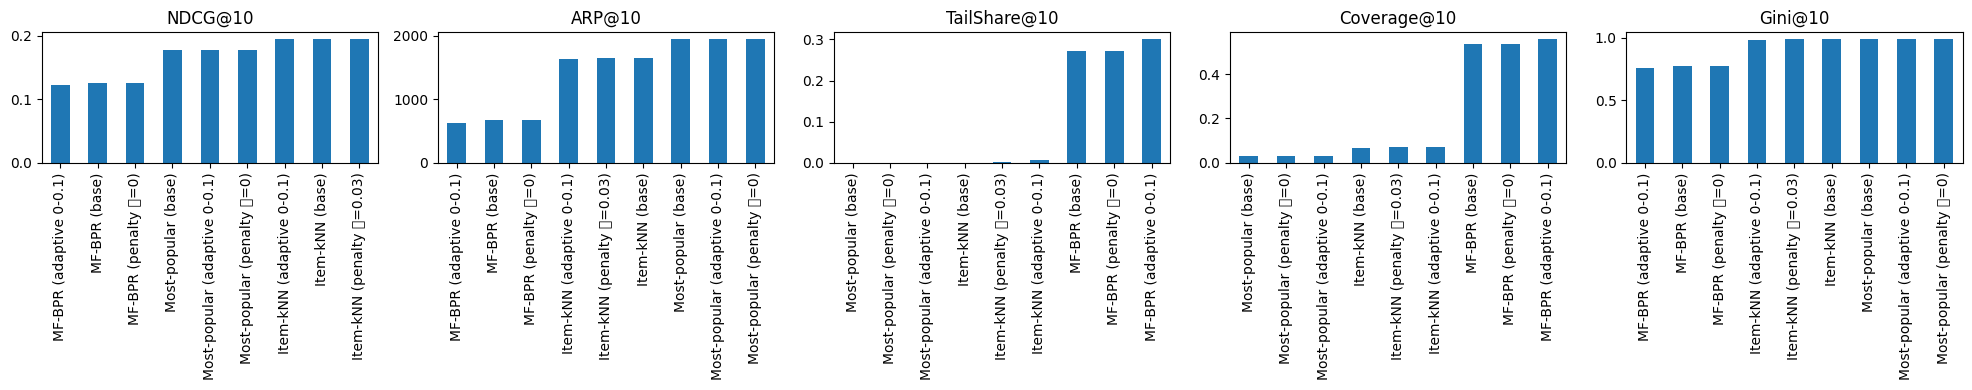

/tmp/ipykernel_1306/1530048521.py:18: UserWarning: Glyph 1 () missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1306/1530048521.py:19: UserWarning: Glyph 1 () missing from font(s) DejaVu Sans.
  plt.savefig("phase3_accuracy_diversity_tradeoff.png",dpi=160,bbox_inches="tight")


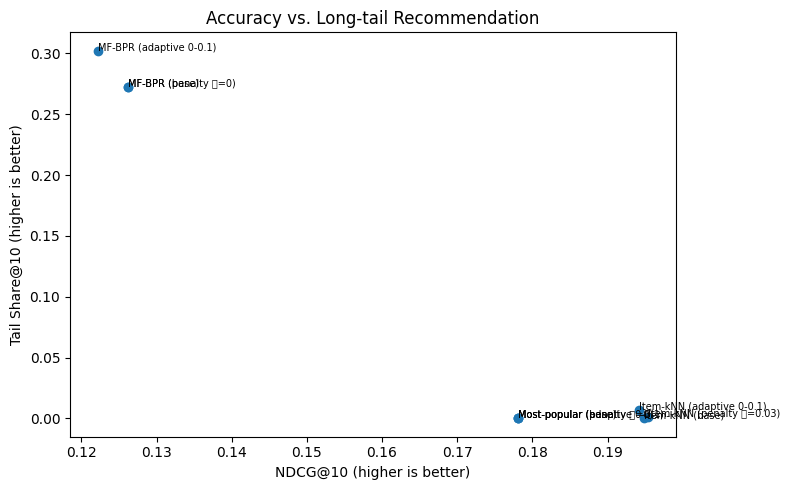

In [ ]:
plot_metrics=["NDCG@10","ARP@10","TailShare@10","Coverage@10","Gini@10"]
fig,axes=plt.subplots(1,len(plot_metrics),figsize=(20,4))
for ax,metric in zip(axes,plot_metrics):
    final_results[metric].sort_values().plot.bar(ax=ax,rot=90)
    ax.set_title(metric)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("phase3_comparison.png",dpi=160,bbox_inches="tight")
plt.show()

fig,ax=plt.subplots(figsize=(8,5))
ax.scatter(final_results["NDCG@10"],final_results["TailShare@10"])
for label,row in final_results.iterrows():
    ax.annotate(label,(row["NDCG@10"],row["TailShare@10"]),fontsize=7)
ax.set_xlabel("NDCG@10 (higher is better)")
ax.set_ylabel("Tail Share@10 (higher is better)")
ax.set_title("Accuracy vs. Long-tail Recommendation")
plt.tight_layout()
plt.savefig("phase3_accuracy_diversity_tradeoff.png",dpi=160,bbox_inches="tight")
plt.show()

## 13. Results interpretation

In [ ]:
comparison=[]
p_val = best_penalty["MF-BPR"]
a_lo, a_hi = best_adaptive["MF-BPR"]

# Safely resolve the index labels dynamically by matching substrings to prevent character mismatch
penalty_label = [idx for idx in final_results.index if "MF-BPR" in idx and "penalty" in idx][0]
adaptive_label = [idx for idx in final_results.index if "MF-BPR" in idx and "adaptive" in idx][0]

for metric in ["NDCG@10","Recall@10","ARP@10","TailShare@10","Coverage@10","Gini@10"]:
    comparison.append({"Metric":metric,
                       "MF-BPR baseline":final_results.loc["MF-BPR (base)",metric],
                       "MF-BPR fixed penalty":final_results.loc[penalty_label,metric],
                       "MF-BPR adaptive":final_results.loc[adaptive_label,metric]})
display(pd.DataFrame(comparison).round(4))

,Metric,MF-BPR baseline,MF-BPR fixed penalty,MF-BPR adaptive
0,NDCG@10,0.1262,0.1262,0.1222
1,Recall@10,0.0420,0.0420,0.0411
2,ARP@10,677.6785,677.6785,631.0604
3,TailShare@10,0.2724,0.2724,0.3023
4,Coverage@10,0.5366,0.5366,0.5603
5,Gini@10,0.7720,0.7720,0.7529


## 14. Export artifacts

In [ ]:
# Tables and figures are saved in the current notebook directory.
print("Saved: phase3_final_results.csv, phase3_user_group_results.csv, phase3_ablation_results.csv")
print("Saved: phase3_calibration_results.csv")
print("Saved: phase3_comparison.png and phase3_accuracy_diversity_tradeoff.png")


Saved: phase3_final_results.csv, phase3_user_group_results.csv, phase3_ablation_results.csv
Saved: phase3_calibration_results.csv
Saved: phase3_comparison.png and phase3_accuracy_diversity_tradeoff.png


## Reproducibility notes
- Random seed is fixed at 42 for initialization.
- Hyperparameter selection uses validation only.
- Final recommender models are refit on train+validation before test evaluation.
- The decision tree is trained on validation candidate outcomes and evaluated on test candidate outcomes.
- Run the notebook in a Python environment with NumPy, pandas, SciPy, Matplotlib, PyTorch, and scikit-learn.
- MovieLens 1M is downloaded automatically on first run; internet access is required for that first download.


## 16. Popularity-profile calibration (Head / Middle / Tail)

This experiment compares the popularity distribution of each user's historical interactions with the distribution in the recommended list. The groups are formed from item popularity in the training data. KL divergence is lower when the recommended list's distribution is closer to the user's historical profile. A small smoothing value prevents log(0).

In [ ]:
# Popularity groups based on final train+validation item popularity.
p33, p67 = np.quantile(final_pop, [1/3, 2/3])
item_group = np.where(final_pop >= p67, "Head", np.where(final_pop <= p33, "Tail", "Middle"))
group_names = ["Head", "Middle", "Tail"]

def profile_calibration(top_lists, eval_users, history_matrix, item_group, eps=1e-8):
    rows=[]
    for u, recs in zip(eval_users, top_lists):
        hist_items=history_matrix[u].indices
        hist_counts=np.array([(item_group[hist_items]==g).sum() for g in group_names],dtype=float)
        rec_counts=np.array([(item_group[recs[:10]]==g).sum() for g in group_names],dtype=float)
        p=(hist_counts+eps)/(hist_counts.sum()+eps*len(group_names))
        q=(rec_counts+eps)/(rec_counts.sum()+eps*len(group_names))
        kl=float(np.sum(p*np.log(p/q)))
        rows.append({"user":u,"KL_Calibration":kl,
                     "History_Head":p[0],"History_Middle":p[1],"History_Tail":p[2],
                     "Rec_Head":q[0],"Rec_Middle":q[1],"Rec_Tail":q[2]})
    return pd.DataFrame(rows)

calibration_rows=[]
for method in ["MF-BPR (base)","MF-BPR (penalty)","MF-BPR (adaptive)"]:
    cal=profile_calibration(final_top[method],users,X_final,item_group)
    calibration_rows.append({"Method":method,"Mean_KL":cal.KL_Calibration.mean(),
                             "Median_KL":cal.KL_Calibration.median()})
calibration_results=pd.DataFrame(calibration_rows)
display(calibration_results.round(4))
calibration_results.to_csv("phase3_calibration_results.csv",index=False)


,Method,Mean_KL,Median_KL
0,MF-BPR (base),0.9470,0.6308
1,MF-BPR (penalty),0.9470,0.6308
2,MF-BPR (adaptive),0.8694,0.5370


## 17. Decision Tree experiment: explaining recommendation hits and misses

The Decision Tree is **not replacing the recommender**. It is an interpretability experiment that learns from the validation recommendation candidates whether a candidate is likely to match a user's held-out future interaction. Features include recommendation score, item popularity, popularity group, user history's head-item share, and candidate rank.

The tree is trained on validation candidates and evaluated on test candidates. Its rules and feature importance help explain which factors are associated with recommendation success.

Decision Tree evaluation on test candidate recommendations
              precision    recall  f1-score   support

           0       0.93      0.52      0.66     20479
           1       0.15      0.68      0.25      2601

    accuracy                           0.54     23080
   macro avg       0.54      0.60      0.46     23080
weighted avg       0.84      0.54      0.62     23080

ROC-AUC: 0.6263559548130239


,Feature,Importance
2,log_popularity,0.609297
3,user_head_share,0.194055
1,score,0.155997
0,rank,0.040651
4,popularity_group_Head,0.000000
5,popularity_group_Middle,0.000000
6,popularity_group_Tail,0.000000


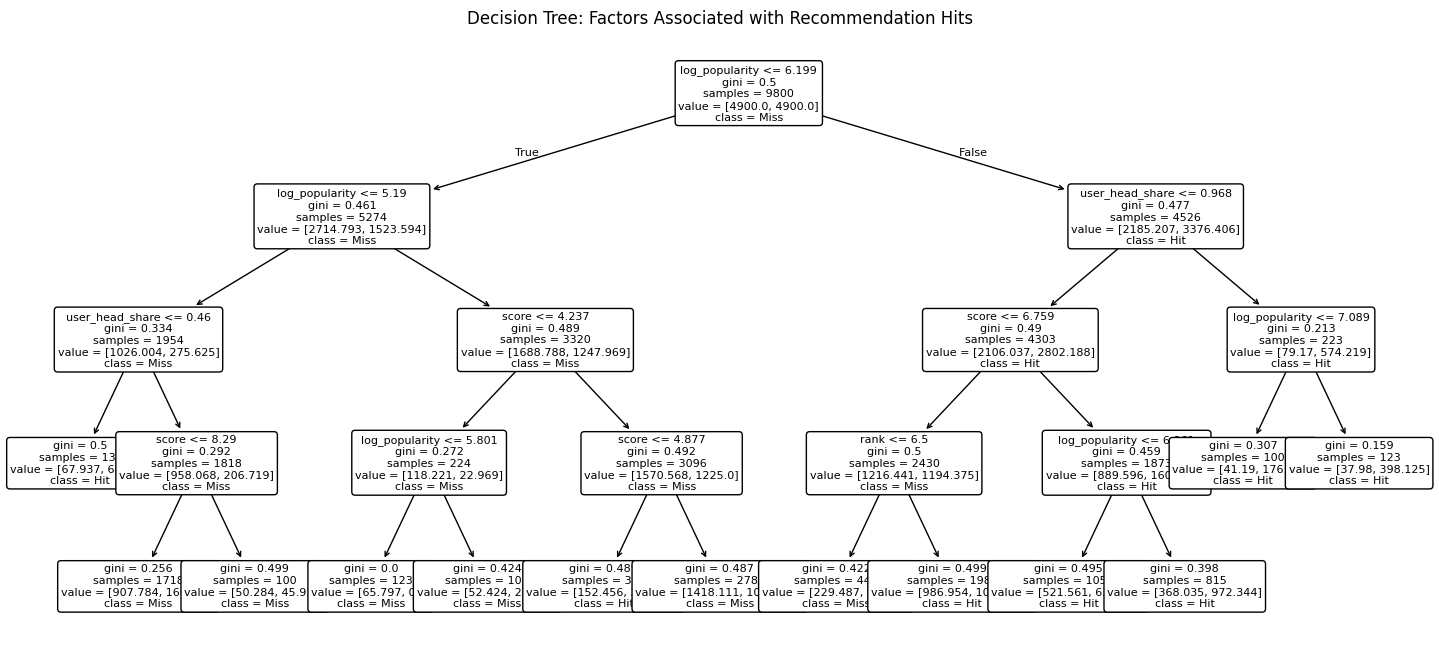

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score

def candidate_features(model, seen, target_data, user_profile, popularity, groups, k=20):
    target_dict=target_data.groupby("user").item.apply(set).to_dict()
    eval_users=np.array([u for u in target_dict if seen[u].nnz>0],dtype=int)
    rows=[]
    for start in range(0,len(eval_users),256):
        batch_users=eval_users[start:start+256]
        score=model.score(batch_users)
        top=get_topk(score,seen[batch_users],k)
        for u, items in zip(batch_users,top):
            for rank,item in enumerate(items,1):
                rows.append({"user":u,"item":int(item),"rank":rank,
                            "score":float(score[np.where(batch_users==u)[0][0],item]),
                            "log_popularity":float(np.log1p(popularity[item])),
                            "user_head_share":float(user_profile[u]),
                            "popularity_group":str(groups[item]),
                            "hit":int(item in target_dict[u])})
    return pd.DataFrame(rows)

# Validation candidates are generated by the model trained only on training data.
val_candidates=candidate_features(baseline_models["MF-BPR"],X_train,val,
                                  user_head_share,item_pop,item_group,k=20)
# Test candidates are generated by the final MF-BPR trained on train+validation.
test_candidates=candidate_features(final_models["MF-BPR"],X_final,test,
                                   final_user_head_share,final_pop,item_group,k=20)

feature_cols=["rank","score","log_popularity","user_head_share"]
tree_train=pd.get_dummies(val_candidates[feature_cols+["popularity_group"]],columns=["popularity_group"])
tree_test=pd.get_dummies(test_candidates[feature_cols+["popularity_group"]],columns=["popularity_group"])
tree_test=tree_test.reindex(columns=tree_train.columns,fill_value=0)

tree=DecisionTreeClassifier(max_depth=4,min_samples_leaf=100,class_weight="balanced",random_state=SEED)
tree.fit(tree_train,val_candidates.hit)
tree_pred=tree.predict(tree_test)
tree_prob=tree.predict_proba(tree_test)[:,1]
print("Decision Tree evaluation on test candidate recommendations")
print(classification_report(test_candidates.hit,tree_pred,zero_division=0))
print("ROC-AUC:",roc_auc_score(test_candidates.hit,tree_prob))
display(pd.DataFrame({"Feature":tree_train.columns,"Importance":tree.feature_importances_}).sort_values("Importance",ascending=False))

plt.figure(figsize=(18,8))
plot_tree(tree,feature_names=list(tree_train.columns),class_names=["Miss","Hit"],
          filled=False,rounded=True,fontsize=8)
plt.title("Decision Tree: Factors Associated with Recommendation Hits")
plt.show()


## 18. Model Performance and Popularity Bias Analysis
Baseline models learn from historical interactions. Popular items have more interactions, so they provide stronger collaborative signals and are more likely to be recommended. This increases popularity bias and reduces exposure to less popular items.

The popularity-penalty method subtracts a popularity-based penalty from recommendation scores, allowing less popular items to rank higher. This can increase tail exposure and coverage, but may reduce accuracy if those items are less relevant.

The adaptive method adjusts the penalty based on each user's historical preferences. This allows different users to receive different levels of debiasing instead of applying the same penalty to everyone.

The Decision Tree experiment helps explain recommendation hits and misses by identifying important features such as item popularity, recommendation rank, and model score.

According to the results, Item-kNN achieved the highest Recall@10 (0.0518) and NDCG@10 (0.1949) among the baseline models. The adaptive MF-BPR method reduced ARP@10 from 677.68 to 631.06 and increased Tail Share@10 from 0.2724 to 0.3023. Coverage also increased from 0.5366 to 0.5603, while Gini decreased from 0.7720 to 0.7529.

The adaptive method reduced popularity bias and improved item diversity, but slightly reduced NDCG@10 from 0.1262 to 0.1222. This shows the trade-off between recommendation accuracy and reducing popularity bias.

The Decision Tree identified item popularity as the most important feature (60.9%), followed by user historical popularity (19.4%) and model score (15.6%). This suggests that popularity plays an important role in recommendation outcomes.

Overall, the experiments show that debiasing can increase exposure to less popular items and improve recommendation diversity, although it may slightly reduce accuracy.

In [ ]:
# Compact final summary table for report-writing
report_summary=final_results[["Recall@10","NDCG@10","ARP@10","TailShare@10","Coverage@10","Gini@10"]].copy()
display(report_summary.sort_values("NDCG@10",ascending=False).round(4))


,Recall@10,NDCG@10,ARP@10,TailShare@10,Coverage@10,Gini@10
Item-kNN (penalty =0.03),0.0522,0.1954,1641.1041,0.0008,0.0691,0.9846
Item-kNN (base),0.0518,0.1949,1645.0160,0.0003,0.0646,0.9849
Item-kNN (adaptive 0-0.1),0.0520,0.1941,1628.3927,0.0067,0.0717,0.9842
Most-popular (base),0.0457,0.1780,1953.5511,0.0000,0.0307,0.9923
Most-popular (adaptive 0-0.1),0.0457,0.1780,1953.5511,0.0000,0.0307,0.9923
Most-popular (penalty =0),0.0457,0.1780,1953.5511,0.0000,0.0307,0.9923
MF-BPR (base),0.0420,0.1262,677.6785,0.2724,0.5366,0.7720
MF-BPR (penalty =0),0.0420,0.1262,677.6785,0.2724,0.5366,0.7720
MF-BPR (adaptive 0-0.1),0.0411,0.1222,631.0604,0.3023,0.5603,0.7529


## 19. Additional models : EASE and LightGCN

 These are added as further baselines. Because these models are more computationally demanding.

In [ ]:
class EASE:
    """Embarrassingly Shallow Autoencoder for sparse item-item recommendation."""
    def __init__(self, reg=500.0):
        self.reg = reg
    def fit(self, X):
        G = (X.T @ X).toarray().astype(np.float64)
        G[np.diag_indices_from(G)] += self.reg
        P = np.linalg.inv(G)
        B = -P / np.diag(P)[None, :]
        np.fill_diagonal(B, 0.0)
        self.B = B.astype(np.float32)
        self.X = X
        return self
    def score(self, users):
        return np.asarray(self.X[users] @ self.B)

ease_model = EASE(reg=500).fit(X_train)
ease_val, _, _ = evaluate_scores(ease_model.score, X_train, val, item_pop, head_mask)
print("EASE validation:", pd.Series(ease_val).round(4))

EASE validation: Recall@10          0.0594
Recall@20          0.0906
NDCG@10            0.1103
NDCG@20            0.1113
ARP@10          1091.6169
TailShare@10       0.0078
Coverage@10        0.1517
Gini@10            0.9452
EvalUsers        490.0000
dtype: float64


### LightGCN implementation

LightGCN propagates user/item embeddings over the bipartite interaction graph. This cell uses BPR training and a small configurable number of propagation layers.

In [ ]:
class LightGCN:
    def __init__(self, dim=32, layers=2, lr=0.005, reg=1e-4, epochs=10, batch=2048, seed=SEED):
        self.dim,self.layers,self.lr,self.reg,self.epochs,self.batch,self.seed = dim,layers,lr,reg,epochs,batch,seed
    def fit(self, X):
        import torch
        import torch.nn.functional as F
        torch.manual_seed(self.seed)
        n_users,n_items=X.shape
        coo=X.tocoo()
        rows=np.concatenate([coo.row, n_users+coo.col]); cols=np.concatenate([n_users+coo.col, coo.row])
        A=sp.coo_matrix((np.ones(len(rows)),(rows,cols)),shape=(n_users+n_items,n_users+n_items)).tocsr()
        deg=np.asarray(A.sum(axis=1)).ravel(); d=np.power(np.maximum(deg,1),-0.5)
        norm=(sp.diags(d)@A@sp.diags(d)).tocoo()
        device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
        adj=torch.sparse_coo_tensor(torch.tensor(np.vstack([norm.row,norm.col]),dtype=torch.long),
            torch.tensor(norm.data,dtype=torch.float32),size=norm.shape,device=device).coalesce()
        users=torch.tensor(coo.row,dtype=torch.long,device=device); pos=torch.tensor(coo.col,dtype=torch.long,device=device)
        emb=torch.nn.Embedding(n_users+n_items,self.dim).to(device); torch.nn.init.normal_(emb.weight,std=.1)
        opt=torch.optim.Adam(emb.parameters(),lr=self.lr)
        for ep in range(self.epochs):
            perm=torch.randperm(len(users),device=device)
            for st in range(0,len(perm),self.batch):
                ix=perm[st:st+self.batch]; u=users[ix]; p=pos[ix]; n=torch.randint(n_items,(len(ix),),device=device)
                base=emb.weight; propagated=[base]
                for _ in range(self.layers): propagated.append(torch.sparse.mm(adj,propagated[-1]))
                final=torch.stack(propagated).mean(0)
                eu,epv,env=final[u],final[n_users+p],final[n_users+n]
                loss=-F.logsigmoid((eu*(epv-env)).sum(1)).mean()
                loss+=self.reg*(base[u].square().sum(1)+base[n_users+p].square().sum(1)).mean()
                opt.zero_grad(); loss.backward(); opt.step()
            print(f"LightGCN epoch {ep+1}/{self.epochs}")
        with torch.no_grad():
            prop=[emb.weight]
            for _ in range(self.layers): prop.append(torch.sparse.mm(adj,prop[-1]))
            final=torch.stack(prop).mean(0).cpu().numpy()
        self.U=final[:n_users]; self.V=final[n_users:]; return self
    def score(self, users): return self.U[users]@self.V.T

lightgcn_model=LightGCN(epochs=10,layers=2).fit(X_train)
lightgcn_val,_,_=evaluate_scores(lightgcn_model.score,X_train,val,item_pop,head_mask)
print("LightGCN validation:",pd.Series(lightgcn_val).round(4))

/tmp/ipykernel_1306/3965658114.py:15: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  adj=torch.sparse_coo_tensor(torch.tensor(np.vstack([norm.row,norm.col]),dtype=torch.long),


LightGCN epoch 1/10
LightGCN epoch 2/10
LightGCN epoch 3/10
LightGCN epoch 4/10
LightGCN epoch 5/10
LightGCN epoch 6/10
LightGCN epoch 7/10
LightGCN epoch 8/10
LightGCN epoch 9/10
LightGCN epoch 10/10
LightGCN validation: Recall@10          0.0601
Recall@20          0.0990
NDCG@10            0.1257
NDCG@20            0.1290
ARP@10          1057.1376
TailShare@10       0.0288
Coverage@10        0.1667
Gini@10            0.9431
EvalUsers        490.0000
dtype: float64


## 20. Popularity-weighted BPR loss
down-weight positive interactions involving highly popular items. This variant applies a weight to each BPR training pair based on the positive item's popularity: `weight(i) = (1 + popularity(i)) ** (-alpha)`. Weights are normalized to mean 1 so the loss scale remains comparable. Alpha is selected on validation NDCG@10.

In [ ]:
class WeightedMFBPR(MFBPR):
    def __init__(self, alpha=0.5, **kwargs): super().__init__(**kwargs); self.alpha=alpha
    def fit(self,X):
        import torch
        import torch.nn.functional as F
        torch.manual_seed(self.seed)
        coo=X.tocoo(); users=torch.tensor(coo.row,dtype=torch.long); pos=torch.tensor(coo.col,dtype=torch.long)
        pop=np.asarray(X.sum(axis=0)).ravel(); w=(1+pop[coo.col])**(-self.alpha); w=w/(w.mean()+1e-12)
        weights=torch.tensor(w,dtype=torch.float32)
        U=torch.nn.Embedding(X.shape[0],self.dim); V=torch.nn.Embedding(X.shape[1],self.dim)
        torch.nn.init.normal_(U.weight,std=.1); torch.nn.init.normal_(V.weight,std=.1)
        opt=torch.optim.Adam(list(U.parameters())+list(V.parameters()),lr=self.lr)
        for ep in range(self.epochs):
            perm=torch.randperm(len(users))
            for st in range(0,len(perm),self.batch):
                b=perm[st:st+self.batch]; u,p=users[b],pos[b]; n=torch.randint(0,X.shape[1],(len(b),))
                eu,epv,env=U(u),V(p),V(n); pair=-F.logsigmoid((eu*(epv-env)).sum(1))
                loss=(pair*weights[b]).mean()+self.reg*(eu.square().sum(1)+epv.square().sum(1)+env.square().sum(1)).mean()
                opt.zero_grad(); loss.backward(); opt.step()
        self.Uw=U.weight.detach().cpu().numpy(); self.Vw=V.weight.detach().cpu().numpy(); return self

weighted_tuning=[]
for alpha in [0.0,0.25,0.5,0.75,1.0]:
    wm=WeightedMFBPR(alpha=alpha,epochs=15,seed=SEED).fit(X_train)
    rr,_,_=evaluate_scores(wm.score,X_train,val,item_pop,head_mask)
    weighted_tuning.append({"alpha":alpha,**rr})
weighted_tuning_df=pd.DataFrame(weighted_tuning); display(weighted_tuning_df.sort_values("NDCG@10",ascending=False))
best_weighted_alpha=float(weighted_tuning_df.sort_values("NDCG@10",ascending=False).iloc[0].alpha)
weighted_final=WeightedMFBPR(alpha=best_weighted_alpha,epochs=15,seed=SEED).fit(X_final)
weighted_test,weighted_top,weighted_users=evaluate_scores(weighted_final.score,X_final,test,final_pop,final_head_mask)
print("Weighted MF-BPR final test:",pd.Series(weighted_test).round(4))

,alpha,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
0,0.00,0.046224,0.084385,0.085128,0.092498,710.548584,0.185510,0.34720,0.844146,490
1,0.25,0.044472,0.069493,0.077119,0.082130,529.388794,0.315102,0.43136,0.778185,490
2,0.50,0.027986,0.055319,0.059395,0.065699,376.297974,0.471633,0.50304,0.713636,490
3,0.75,0.023062,0.044784,0.047330,0.052808,272.159180,0.610204,0.53984,0.679529,490
4,1.00,0.017866,0.039751,0.036346,0.043888,194.378769,0.728776,0.55616,0.664282,490


Weighted MF-BPR final test: Recall@10          0.0464
Recall@20          0.0812
NDCG@10            0.1402
NDCG@20            0.1418
ARP@10           811.5242
TailShare@10       0.1981
Coverage@10        0.4675
Gini@10            0.8241
EvalUsers       1154.0000
dtype: float64


## 21. Personalized calibrated reranking

reranking idea is to match a user's historical Head/Middle/Tail popularity profile. We first take the model's top 100 candidates, then select a top-10 list whose popularity-group distribution is close to that user's history. The implementation greedily rewards items from groups that are underrepresented relative to the user's profile. This is an interpretable approximation to calibrated reranking, not an exact optimizer.

In [ ]:
def personalized_calibrated_rerank(base_model, users, seen_matrix, history_matrix, item_groups, candidate_k=100, final_k=10):
    group_order=["Head","Middle","Tail"]
    base_scores=base_model.score(users); candidates=get_topk(base_scores,seen_matrix[users],candidate_k); out=[]
    for row_idx,u in enumerate(users):
        hist=history_matrix[u].indices
        counts=np.array([(item_groups[hist]==g).sum() for g in group_order],float)
        profile=(counts+1e-6)/(counts.sum()+3e-6); selected=[]; group_counts=np.zeros(3); remaining=list(candidates[row_idx])
        for _ in range(final_k):
            best_item=None; best_value=-np.inf
            for item in remaining:
                gi=group_order.index(item_groups[item]); deficit=profile[gi]*final_k-group_counts[gi]
                value=base_scores[row_idx,item]+0.05*deficit
                if value>best_value: best_value=value; best_item=item
            selected.append(best_item); group_counts[group_order.index(item_groups[best_item])]+=1; remaining.remove(best_item)
        out.append(selected)
    return np.asarray(out)

cal_users=np.array([u for u in test.groupby("user").item.apply(set).index if X_final[u].nnz>0],dtype=int)
cal_top=personalized_calibrated_rerank(final_models["MF-BPR"],cal_users,X_final,X_final,item_group,100,10)
target_dict=test.groupby("user").item.apply(set).to_dict()
cal_hits=np.array([[int(i in target_dict[u]) for i in row] for u,row in zip(cal_users,cal_top)])
cal_rec=np.mean([hits.sum()/max(1,len(target_dict[u])) for hits,u in zip(cal_hits,cal_users)])
cal_ndcg=[]
for hits in cal_hits:
    dcg=(hits/np.log2(np.arange(2,12))).sum(); ideal=(1/np.log2(np.arange(2,min(10,hits.sum())+2))).sum()
    cal_ndcg.append(dcg/ideal if ideal>0 else 0)
cal_counts=np.bincount(cal_top.ravel(),minlength=n_items)
cal_metrics={"Recall@10":cal_rec,"NDCG@10":np.mean(cal_ndcg),"ARP@10":final_pop[cal_top].mean(),
             "TailShare@10":1-final_head_mask[cal_top].mean(),"Coverage@10":np.count_nonzero(cal_counts)/n_items,
             "Gini@10":gini(cal_counts)}
display(pd.Series(cal_metrics).round(4))

,0
Recall@10,0.0420
NDCG@10,0.3004
ARP@10,679.5244
TailShare@10,0.2701
Coverage@10,0.5334
Gini@10,0.7736


## 22. Amazon dataset extension (file-based)

A second Amazon category dataset. Amazon review files are large and schemas vary by release. This cell supports a local JSON-lines or CSV file.

In [ ]:
AMAZON_PATH_JSON="data/amazon_reviews.json"; AMAZON_PATH_CSV="data/amazon_reviews.csv"
def load_amazon_reviews(path):
    d=pd.read_json(path,lines=True) if path.endswith(".json") else pd.read_csv(path)
    column_map={"reviewerID":"user","asin":"item","overall":"rating","unixReviewTime":"ts","user_id":"user","item_id":"item","timestamp":"ts"}
    d=d.rename(columns={k:v for k,v in column_map.items() if k in d.columns})
    required={"user","item","rating"}; missing=required-set(d.columns)
    if missing: raise ValueError(f"Missing required fields: {missing}. Update column_map.")
    if "ts" not in d.columns:
        d["ts"]=np.arange(len(d)); print("WARNING: no timestamp field; synthetic row-order timestamps used. Not a valid temporal benchmark.")
    d=d[["user","item","rating","ts"]].dropna(); d["ts"]=pd.to_numeric(d["ts"],errors="coerce").fillna(0); return d
# Uncomment after placing a compatible file:
# amazon_raw=load_amazon_reviews(AMAZON_PATH_JSON)
# amazon_train,amazon_val,amazon_test,amazon_users,amazon_items=prepare_data(amazon_raw,min_rating=4,k=5)

## 23. Repeated-seed robustness experiment

In [ ]:
seed_results=[]
for seed in [7,42,2026]:
    # Instantiate first and fit separately so seed_model is not None
    seed_model = MFBPR(epochs=10, seed=seed)
    seed_model.fit(X_train)
    seed_metrics,_,_ = evaluate_scores(seed_model.score, X_train, val, item_pop, head_mask)
    seed_results.append({"seed":seed, **seed_metrics})
seed_results_df=pd.DataFrame(seed_results); display(seed_results_df.round(4))
display(seed_results_df.drop(columns="seed").agg(["mean","std"]).round(4))
seed_results_df.to_csv("phase3_seed_robustness.csv", index=False)

Epoch 01/10 | loss 0.6003
Epoch 02/10 | loss 0.3278
Epoch 03/10 | loss 0.2690
Epoch 04/10 | loss 0.2371
Epoch 05/10 | loss 0.2172
Epoch 06/10 | loss 0.2038
Epoch 07/10 | loss 0.1925
Epoch 08/10 | loss 0.1834
Epoch 09/10 | loss 0.1786
Epoch 10/10 | loss 0.1713
Epoch 01/10 | loss 0.5995
Epoch 02/10 | loss 0.3354
Epoch 03/10 | loss 0.2712
Epoch 04/10 | loss 0.2371
Epoch 05/10 | loss 0.2166
Epoch 06/10 | loss 0.2030
Epoch 07/10 | loss 0.1915
Epoch 08/10 | loss 0.1848
Epoch 09/10 | loss 0.1776
Epoch 10/10 | loss 0.1719
Epoch 01/10 | loss 0.5826
Epoch 02/10 | loss 0.3349
Epoch 03/10 | loss 0.2746
Epoch 04/10 | loss 0.2390
Epoch 05/10 | loss 0.2171
Epoch 06/10 | loss 0.2029
Epoch 07/10 | loss 0.1916
Epoch 08/10 | loss 0.1836
Epoch 09/10 | loss 0.1773
Epoch 10/10 | loss 0.1711


,seed,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
0,7,0.0475,0.0839,0.0948,0.1011,808.8694,0.1300,0.2950,0.8817,490
1,42,0.0442,0.0848,0.0906,0.0992,798.4681,0.1327,0.2970,0.8779,490
2,2026,0.0518,0.0858,0.0967,0.1036,798.1835,0.1416,0.3046,0.8770,490


,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
mean,0.0479,0.0849,0.0940,0.1013,801.8403,0.1348,0.2989,0.8788,490.0
std,0.0038,0.0010,0.0031,0.0022,6.0890,0.0061,0.0051,0.0025,0.0


## 24. Why the methods work

- **Most-Popular:** interaction counts directly rank items, so high-exposure items dominate. This creates strong popularity bias and little personalization.
- **Item-kNN:** recommendations are based on similarity to items in a user's history. Popular items have more co-occurrences and can obtain more stable similarity estimates.
- **MF-BPR:** pairwise ranking learns user/item latent factors from positive-vs-negative comparisons. It can personalize beyond raw popularity, but sparse interactions and popular-item exposure can still influence embeddings.
- **EASE:** learns a linear item-item relationship from the interaction matrix. It can capture co-occurrence patterns efficiently, but those patterns may reflect popularity.
- **LightGCN:** graph propagation aggregates neighboring user/item information. This can improve collaborative signal, while high-degree popular nodes may have greater influence.
- **Popularity-weighted BPR:** reduces the contribution of popular positive items during training. This may improve tail exposure but can reduce accuracy if popular items are genuinely relevant.
- **Popularity-penalty reranking:** changes final scores without retraining. Increasing the penalty pushes recommendations toward less popular items, producing an accuracy-diversity trade-off.
- **Personalized calibrated reranking:** targets a user's own historical popularity profile instead of imposing one global distribution. It may improve preference alignment, but a user's history can itself be biased.
- **Decision Tree:** is an explanation model for candidate-level hit/miss outcomes. It describes associations in the generated candidates; it does not establish causal explanations.

## 25. Final expanded comparison

This cell gathers additional experiments. Keep the extension results separate from the core benchmark so the final report distinguishes the main evaluation from experiments with reduced training settings.

In [ ]:
extended_rows=[{"Model":"EASE","Split":"Validation",**ease_val},
              {"Model":"LightGCN","Split":"Validation",**lightgcn_val},
              {"Model":"Weighted MF-BPR","Split":"Test",**weighted_test},
              {"Model":"Personalized calibrated reranking","Split":"Test",**cal_metrics}]
extended_results=pd.DataFrame(extended_rows); display(extended_results.round(4))
extended_results.to_csv("phase3_extended_results.csv",index=False)

,Model,Split,Recall@10,Recall@20,NDCG@10,NDCG@20,ARP@10,TailShare@10,Coverage@10,Gini@10,EvalUsers
0,EASE,Validation,0.0594,0.0906,0.1103,0.1113,1091.6169,0.0078,0.1517,0.9452,490.0
1,LightGCN,Validation,0.0601,0.0990,0.1257,0.1290,1057.1376,0.0288,0.1667,0.9431,490.0
2,Weighted MF-BPR,Test,0.0464,0.0812,0.1402,0.1418,811.5242,0.1981,0.4675,0.8241,1154.0
3,Personalized calibrated reranking,Test,0.0420,NaN,0.3004,NaN,679.5244,0.2701,0.5334,0.7736,NaN
